<center><h1> Sathiya_Rohith_HW7</h1></center>

Name: Rohith Sathiya
<br>Github Username: Rohith-s9401
<br>USC ID: 7480930295

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### Import packages

In [1]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as SamplingPipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, pairwise_distances
from joblib import Parallel, delayed, parallel_config
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df = pd.read_csv('data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv')

X = df.drop(
    columns=['Family', 'Genus', 'Species', 'RecordID']
)

y = df[['Family', 'Genus', 'Species']].copy()

# Random 70/30 split for supervised classification.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.7,
    random_state=42,
    shuffle=True
)

print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (5036, 22)
X_test: (2159, 22)
y_train: (5036, 3)
y_test: (2159, 3)


### (b) Train a classifier for each label

### (i) Evaluation

In multilabel classification, each instance may be associated with multiple labels, so evaluation metrics must consider performance across all outputs. In this dataset, each instance has three categorical outputs: Family, Genus, and Species.

**Exact Match (Subset Accuracy)** is a strict metric that counts a prediction as correct only when the entire predicted label triplet exactly matches the true triplet for an instance. If even one output is predicted incorrectly, the whole prediction is considered wrong. Consequently, exact match is a demanding metric and typically decreases as the number of outputs increases.

**Hamming Loss** measures the fraction of output labels that are incorrectly predicted, averaged over all outputs and instances. Here, an incorrect Family, Genus, or Species prediction counts as one mismatch. Since it evaluates errors at the individual-output level, it gives credit for correct outputs even when the complete triplet is incorrect. A smaller Hamming loss indicates better performance.

**Average Hamming Distance** is the mean number of mismatched outputs per observation. It ranges from 0 to 3 in this dataset and equals three times the Hamming loss.

**Hamming Score (Label-wise Accuracy)** is defined here as one minus the Hamming loss and represents the proportion of correctly predicted output labels. Unlike exact match, it evaluates correctness at each output position rather than requiring the entire triplet to match. The term “Hamming score” varies across sources; this notebook uses Hamming score = 1 − Hamming loss.

Higher exact match and Hamming score, and lower Hamming distance and loss, indicate better performance.

#### (ii) Train a SVM for each of the labels

In [3]:
# Evaluation Function
def evaluate(y_true, y_pred, name):
    y_true = y_true.values
    y_pred = y_pred.values
    # Exact Match
    exact = np.mean(np.all(y_true == y_pred, axis=1))
    # Hamming Loss
    h_loss = np.mean(y_true != y_pred)
    # Hamming Score
    h_score = 1 - h_loss
    print(f"\n{name}")
    print("Exact Match:", exact)
    print("Hamming Loss:", h_loss)
    print("Hamming Score:", h_score)

In [5]:
# Candidate hyperparameters
penalty_candidates = [0.1, 1, 10, 100]
gamma_candidates = [0.001, 0.01, 0.1, 1]

raw_search_space = {
    "estimator__C": penalty_candidates,
    "estimator__gamma": gamma_candidates
}

scaled_search_space = {
    "ovr__estimator__C": penalty_candidates,
    "ovr__estimator__gamma": gamma_candidates
}

# Store fitted searches and predictions
raw_svm_searches = {}
scaled_svm_searches = {}
raw_predictions = {}
scaled_predictions = {}

In [6]:
# Gaussian SVMs using raw features
for target_label in y_train.columns:
    print(f"\nTraining raw-feature RBF SVM: {target_label}")

    raw_classifier = OneVsRestClassifier(SVC(kernel="rbf"))

    raw_search = GridSearchCV(
        estimator=raw_classifier,
        param_grid=raw_search_space,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    raw_search.fit(X_train, y_train[target_label])
    print("Selected parameters:", raw_search.best_params_)

    raw_svm_searches[target_label] = raw_search
    raw_predictions[target_label] = raw_search.predict(X_test)

y_pred_raw = pd.DataFrame(
    raw_predictions,
    columns=y_train.columns,
    index=y_test.index
)

evaluate(y_test, y_pred_raw, "GAUSSIAN SVM - RAW FEATURES")

# Gaussian SVMs using standardized features
for target_label in y_train.columns:
    print(f"\nTraining standardized RBF SVM: {target_label}")

    standardized_classifier = Pipeline([
        ("scaler", StandardScaler()),
        ("ovr", OneVsRestClassifier(SVC(kernel="rbf")))
    ])

    standardized_search = GridSearchCV(
        estimator=standardized_classifier,
        param_grid=scaled_search_space,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    standardized_search.fit(
        X_train,
        y_train[target_label]
    )

    print(
        "Selected parameters:",
        standardized_search.best_params_
    )

    scaled_svm_searches[target_label] = standardized_search
    scaled_predictions[target_label] = (
        standardized_search.predict(X_test)
    )

y_pred_scaled = pd.DataFrame(
    scaled_predictions,
    columns=y_train.columns,
    index=y_test.index
)

evaluate(
    y_test,
    y_pred_scaled,
    "GAUSSIAN SVM - SCALED FEATURES"
)

# Selected parameters and Gaussian widths: sigma = sqrt(1 / (2 * gamma))
kernel_summary_rows = []

search_groups = [
    ("Raw", raw_svm_searches, "estimator__"),
    ("Standardized", scaled_svm_searches, "ovr__estimator__")
]

for feature_mode, trained_searches, parameter_prefix in search_groups:
    for target_label, fitted_search in trained_searches.items():
        selected_parameters = fitted_search.best_params_
        selected_gamma = selected_parameters[parameter_prefix + "gamma"]

        kernel_summary_rows.append({
            "Features": feature_mode,
            "Label": target_label,
            "Best C": selected_parameters[parameter_prefix + "C"],
            "Best gamma": selected_gamma,
            "Gaussian width (sigma)": np.sqrt(1 / (2 * selected_gamma)),
            "Best 10-fold CV accuracy": fitted_search.best_score_
        })

kernel_summary = pd.DataFrame(kernel_summary_rows)
display(kernel_summary)


Training raw-feature RBF SVM: Family
Selected parameters: {'estimator__C': 100, 'estimator__gamma': 1}

Training raw-feature RBF SVM: Genus
Selected parameters: {'estimator__C': 10, 'estimator__gamma': 1}

Training raw-feature RBF SVM: Species
Selected parameters: {'estimator__C': 10, 'estimator__gamma': 1}

GAUSSIAN SVM - RAW FEATURES
Exact Match: 0.9874942102825383
Hamming Loss: 0.0077196232823838196
Hamming Score: 0.9922803767176162

Training standardized RBF SVM: Family
Selected parameters: {'ovr__estimator__C': 10, 'ovr__estimator__gamma': 0.1}

Training standardized RBF SVM: Genus
Selected parameters: {'ovr__estimator__C': 10, 'ovr__estimator__gamma': 0.1}

Training standardized RBF SVM: Species
Selected parameters: {'ovr__estimator__C': 10, 'ovr__estimator__gamma': 0.1}

GAUSSIAN SVM - SCALED FEATURES
Exact Match: 0.9865678554886521
Hamming Loss: 0.010035510267098965
Hamming Score: 0.9899644897329011


,Features,Label,Best C,Best gamma,Gaussian width (sigma),Best 10-fold CV accuracy
0,Raw,Family,100,1.0,0.707107,0.992058
1,Raw,Genus,10,1.0,0.707107,0.990070
2,Raw,Species,10,1.0,0.707107,0.989871
3,Standardized,Family,10,0.1,2.236068,0.991462
4,Standardized,Genus,10,0.1,2.236068,0.989872
5,Standardized,Species,10,0.1,2.236068,0.988482


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [7]:
# Candidate penalty values
l1_penalty_candidates = [0.01, 0.1, 1, 10, 100]
l1_search_space = {"svm__C": l1_penalty_candidates}

# Store fitted searches and predictions
l1_svm_searches = {}
l1_predictions = {}

In [8]:
# L1 SVMs using standardized features
for target_label in y_train.columns:
    print(f"\nTraining standardized L1 SVM: {target_label}")

    standardized_l1_classifier = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        ))
    ])

    l1_search = GridSearchCV(
        estimator=standardized_l1_classifier,
        param_grid=l1_search_space,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    l1_search.fit(X_train, y_train[target_label])
    print("Selected parameters:", l1_search.best_params_)

    l1_svm_searches[target_label] = l1_search
    l1_predictions[target_label] = l1_search.predict(X_test)

# Preserve the prediction dataframe name used in later cells
y_pred_l1 = pd.DataFrame(
    l1_predictions,
    columns=y_train.columns,
    index=y_test.index
)

evaluate(
    y_test,
    y_pred_l1,
    "L1 SVM - SCALED FEATURES (STANDARDIZED)"
)


Training standardized L1 SVM: Family


C:\Users\DELL\anaconda3\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Selected parameters: {'svm__C': 1}

Training standardized L1 SVM: Genus
Selected parameters: {'svm__C': 10}

Training standardized L1 SVM: Species
Selected parameters: {'svm__C': 10}

L1 SVM - SCALED FEATURES (STANDARDIZED)
Exact Match: 0.9129226493747105
Hamming Loss: 0.05681642735834491
Hamming Score: 0.9431835726416551


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [9]:
# Candidate penalty values
smote_penalty_candidates = [0.01, 0.1, 1, 10, 100]
smote_search_space = {"svm__C": smote_penalty_candidates}

# Store fitted searches and predictions
smote_svm_searches = {}
smote_predictions = {}

In [10]:
# L1 SVMs using standardization and SMOTE
for target_label in y_train.columns:
    print(f"\nTraining L1 SVM with SMOTE: {target_label}")

    standardized_smote_classifier = SamplingPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        ))
    ])

    smote_search = GridSearchCV(
        estimator=standardized_smote_classifier,
        param_grid=smote_search_space,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )

    smote_search.fit(X_train, y_train[target_label])
    print("Selected parameters:", smote_search.best_params_)

    smote_svm_searches[target_label] = smote_search
    smote_predictions[target_label] = smote_search.predict(X_test)

# Preserve the prediction dataframe name used in later cells
y_pred_smote = pd.DataFrame(
    smote_predictions,
    columns=y_train.columns,
    index=y_test.index
)

evaluate(
    y_test,
    y_pred_smote,
    "L1 SVM WITH SMOTE"
)


Training L1 SVM with SMOTE: Family
Selected parameters: {'svm__C': 1}

Training L1 SVM with SMOTE: Genus
Selected parameters: {'svm__C': 10}

Training L1 SVM with SMOTE: Species
Selected parameters: {'svm__C': 1}

L1 SVM WITH SMOTE
Exact Match: 0.8522464103751737
Hamming Loss: 0.07735062528948587
Hamming Score: 0.9226493747105141


In [11]:
# Calculate metrics from the number of incorrect outputs per observation
def summarize_predictions(actual, predicted):
    actual_values = np.asarray(actual)
    predicted_values = np.asarray(predicted)

    if actual_values.shape != predicted_values.shape:
        raise ValueError("Actual and predicted labels must have matching shapes.")

    errors_per_sample = np.count_nonzero(
        actual_values != predicted_values,
        axis=1
    )

    exact_match = np.count_nonzero(
        errors_per_sample == 0
    ) / len(errors_per_sample)

    label_error_rate = errors_per_sample.sum() / actual_values.size

    return {
        "Exact Match": exact_match,
        "Hamming Loss": label_error_rate,
        "Hamming Score": 1 - label_error_rate
    }


# Predictions from the four model variants
prediction_sets = {
    "SVM Gaussian (Raw)": y_pred_raw,
    "SVM Gaussian (Standardized)": y_pred_scaled,
    "L1 SVM": y_pred_l1,
    "L1 SVM + SMOTE": y_pred_smote
}

# Build the comparison table using the original test labels
comparison_scores = {
    model_name: summarize_predictions(y_test, predictions)
    for model_name, predictions in prediction_sets.items()
}

results_df = (
    pd.DataFrame.from_dict(comparison_scores, orient="index")
    .rename_axis("Model")
    .reset_index()
)

display(results_df)

,Model,Exact Match,Hamming Loss,Hamming Score
0,SVM Gaussian (Raw),0.987494,0.007720,0.992280
1,SVM Gaussian (Standardized),0.986568,0.010036,0.989964
2,L1 SVM,0.912923,0.056816,0.943184
3,L1 SVM + SMOTE,0.852246,0.077351,0.922649


##### Findings
- The Gaussian SVM without standardization achieved the best overall results, with a **Hamming loss of 0.007720** and an **exact match ratio of 0.987494**.
- The standardized Gaussian SVM performed slightly worse, with a Hamming loss of **0.010036** and an exact match ratio of **0.986568**. Standardization did not improve overall performance on this split.
- The L1-penalized linear SVM produced a Hamming loss of **0.056816** and an exact match ratio of **0.912923**, performing worse overall than both Gaussian models.
- Applying SMOTE to the L1 classifier increased Hamming loss to **0.077351** and reduced the exact match ratio to **0.852246**. Therefore, SMOTE did not improve aggregate predictive performance in this experiment.
- The overall metrics alone do not establish whether SMOTE improved minority-class recall. Per-class precision and recall would be needed to assess that effect.


##### Conclusion

Among the evaluated models, the **Gaussian SVM without standardization** performed best overall, achieving the lowest Hamming loss and highest exact match ratio. Standardization slightly reduced performance on this split, while both Gaussian variants outperformed the L1-penalized linear SVM.

Applying SMOTE reduced both label-wise and complete-triplet accuracy for the L1 classifier. Its effect on minority-class recognition cannot be determined from the aggregate metrics alone and would require per-class precision and recall. These conclusions apply to the evaluated models, parameter grids, and chosen train/test split.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) & (b) Use k-means clustering & Determine which family is the majority

In [12]:
X_cluster = X.to_numpy()
y_cluster = y.reset_index(drop=True)


def majority_by_cluster(cluster_ids, labels):
    majority = {}
    for cluster_id in np.unique(cluster_ids):
        positions = np.flatnonzero(cluster_ids == cluster_id)
        frequencies = labels.iloc[positions].value_counts()
        majority[cluster_id] = frequencies.idxmax()
    return majority


def assess_cluster_predictions(actual, predicted):
    actual_array = np.asarray(actual)
    predicted_array = np.asarray(predicted)

    if actual_array.shape != predicted_array.shape:
        raise ValueError("Actual and predicted labels must have matching shapes.")

    errors_per_row = np.count_nonzero(
        actual_array != predicted_array, axis=1
    )
    exact = np.mean(errors_per_row == 0)
    distance = np.mean(errors_per_row)
    loss = errors_per_row.sum() / actual_array.size

    return exact, distance, loss, 1 - loss


def execute_clustering_run(run_number, predictors, distance_matrix, targets):
    random_seed = 42 + run_number
    candidate_counts = list(range(2, 51))
    candidate_partitions = {}
    silhouette_values = []

    # Fit every candidate and retain its partition.
    for cluster_count in candidate_counts:
        fitted_kmeans = KMeans(
            n_clusters=cluster_count,
            n_init=10,
            random_state=random_seed
        )
        assignments = fitted_kmeans.fit_predict(predictors)

        silhouette_values.append(
            silhouette_score(
                distance_matrix,
                assignments,
                metric="precomputed"
            )
        )
        candidate_partitions[cluster_count] = assignments

    # argmax selects the first maximum, preserving the original tie behavior.
    winning_position = int(np.argmax(silhouette_values))
    selected_k = candidate_counts[winning_position]
    selected_clusters = candidate_partitions[selected_k]

    label_majorities = {
        output: majority_by_cluster(selected_clusters, targets[output])
        for output in targets.columns
    }

    cluster_table = pd.DataFrame({
        "Cluster": np.unique(selected_clusters),
        "Size": np.bincount(selected_clusters)
    })

    predictions = pd.DataFrame(index=targets.index)
    membership_series = pd.Series(selected_clusters, index=targets.index)

    for output in targets.columns:
        cluster_table[output + " (Majority)"] = (
            cluster_table["Cluster"].map(label_majorities[output])
        )
        predictions[output] = membership_series.map(
            label_majorities[output]
        )

    exact, distance, loss, score = assess_cluster_predictions(
        targets, predictions
    )

    return {
        "Run": run_number + 1,
        "Seed": random_seed,
        "Best k": selected_k,
        "Silhouette": silhouette_values[winning_position],
        "Exact Match": exact,
        "Hamming Distance": distance,
        "Hamming Loss": loss,
        "Hamming Score": score,
        "cluster_table": cluster_table,
        "k_values": candidate_counts,
        "sil_scores": silhouette_values
    }


# Compute the full Euclidean distance matrix once.
with threadpool_limits(limits=1):
    cluster_distances = pairwise_distances(
        X_cluster, metric="euclidean"
    )

np.fill_diagonal(cluster_distances, 0.0)

# Execute the 50 independent, reproducible trials.
worker_count = min(4, os.cpu_count() or 1)

with parallel_config(
    backend="loky",
    n_jobs=worker_count,
    inner_max_num_threads=1
):
    trial_results = Parallel(verbose=5, max_nbytes="10M")(
        delayed(execute_clustering_run)(
            run_number, X_cluster, cluster_distances, y_cluster
        )
        for run_number in range(50)
    )

metric_columns = [
    "Run", "Seed", "Best k", "Silhouette", "Exact Match",
    "Hamming Distance", "Hamming Loss", "Hamming Score"
]

monte_carlo_results = pd.DataFrame(trial_results)[metric_columns]
hamming_distances = monte_carlo_results["Hamming Distance"].tolist()

# Preserve names referenced by subsequent summary and plotting cells.
first_run = trial_results[0]
first_run_cluster_table = first_run["cluster_table"].copy()
first_run_metrics = {
    metric: first_run[metric]
    for metric in [
        "Exact Match", "Hamming Distance", "Hamming Loss", "Hamming Score"
    ]
}
first_run_best_k = first_run["Best k"]
first_run_k_values = first_run["k_values"]
first_run_sil_scores = first_run["sil_scores"]

print("Majority label triplets and cluster sizes: first trial")
display(first_run_cluster_table)

print("Evaluation metrics: first trial")
display(pd.DataFrame([first_run_metrics]))

print("First 10 trials; final statistics use all 50:")
display(
    monte_carlo_results[
        ["Run", "Best k", "Hamming Distance", "Hamming Loss", "Hamming Score"]
    ].head(10).round(6)
)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  9.8min
[Parallel(n_jobs=4)]: Done  50 out of  50 | elapsed: 29.3min finished


Majority label triplets and cluster sizes: first trial


,Cluster,Size,Family (Majority),Genus (Majority),Species (Majority)
0,0,3568,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,614,Hylidae,Hypsiboas,HypsiboasCinerascens
2,2,1031,Dendrobatidae,Ameerega,Ameeregatrivittata
3,3,1982,Hylidae,Hypsiboas,HypsiboasCordobae


Evaluation metrics: first trial


,Exact Match,Hamming Distance,Hamming Loss,Hamming Score
0,0.755525,0.667269,0.222423,0.777577


First 10 trials; final statistics use all 50:


,Run,Best k,Hamming Distance,Hamming Loss,Hamming Score
0,1,4,0.667269,0.222423,0.777577
1,2,4,0.667269,0.222423,0.777577
2,3,4,0.666852,0.222284,0.777716
3,4,4,0.667269,0.222423,0.777577
4,5,4,0.667269,0.222423,0.777577
5,6,4,0.667269,0.222423,0.777577
6,7,4,0.667269,0.222423,0.777577
7,8,4,0.667269,0.222423,0.777577
8,9,4,0.667269,0.222423,0.777577
9,10,4,0.840167,0.280056,0.719944


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [13]:
# Calculate summary statistics across the completed trials
summary_metrics = [
    "Hamming Distance",
    "Hamming Score",
    "Hamming Loss"
]

trial_measurements = monte_carlo_results[summary_metrics]

cluster_summary = pd.DataFrame({
    "Mean over 50 trials": trial_measurements.mean(),
    "Sample standard deviation": trial_measurements.std(ddof=1)
})

# Preserve these variables for subsequent cells
distance_trials = np.asarray(hamming_distances, dtype=float)
mean_hamming_distance = distance_trials.mean()
std_hamming_distance = distance_trials.std(ddof=1)

# Count how often each cluster count was selected
selected_k_counts = (
    monte_carlo_results["Best k"]
    .value_counts()
    .sort_index()
    .rename("Trials")
)

print("MONTE CARLO SUMMARY — 50 TRIALS")
display(cluster_summary)

print("Number of trials selecting each k:")
display(selected_k_counts)

print("Hamming distance: average incorrect outputs per observation (0–3).")
print("Hamming loss: Hamming distance divided by 3.")
print("Hamming score: 1 minus Hamming loss.")

MONTE CARLO SUMMARY — 50 TRIALS


,Mean over 50 trials,Sample standard deviation
Hamming Distance,0.676742,0.029603
Hamming Score,0.774419,0.009868
Hamming Loss,0.225581,0.009868


Number of trials selecting each k:


Best k
4    50
Name: Trials, dtype: int64

Hamming distance: average incorrect outputs per observation (0–3).
Hamming loss: Hamming distance divided by 3.
Hamming score: 1 minus Hamming loss.


## 3. ISLR 12.6.2

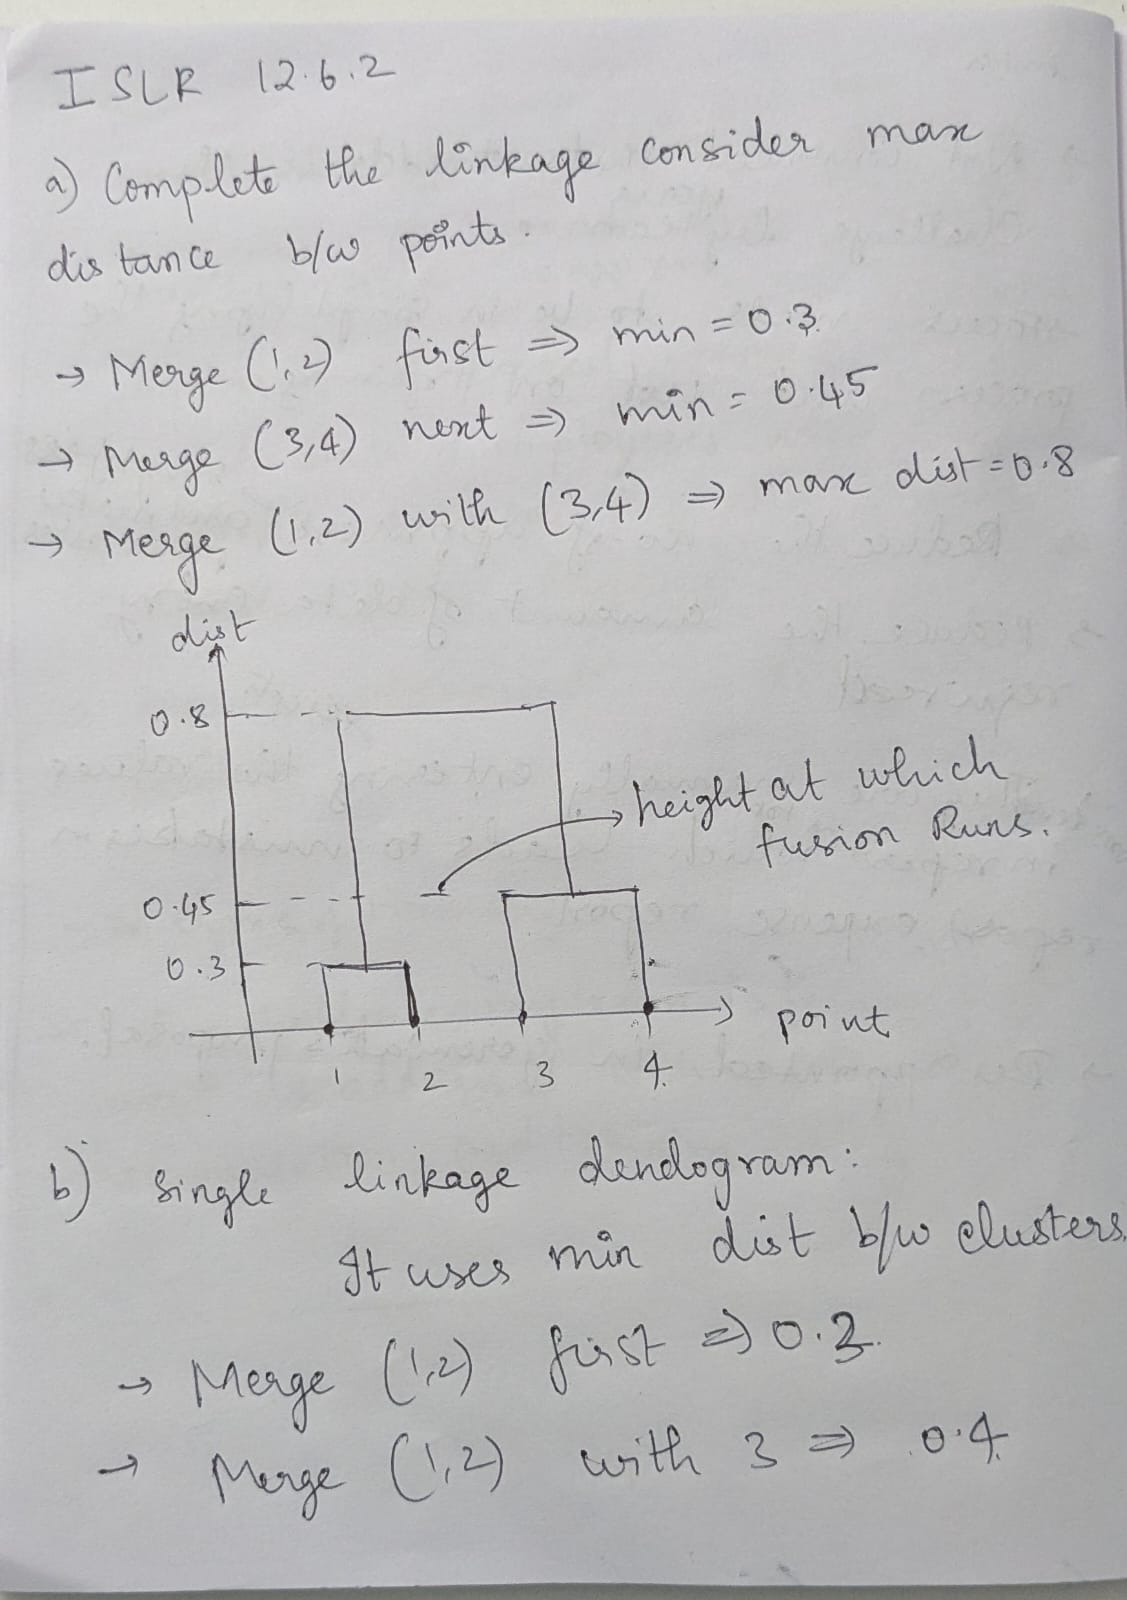

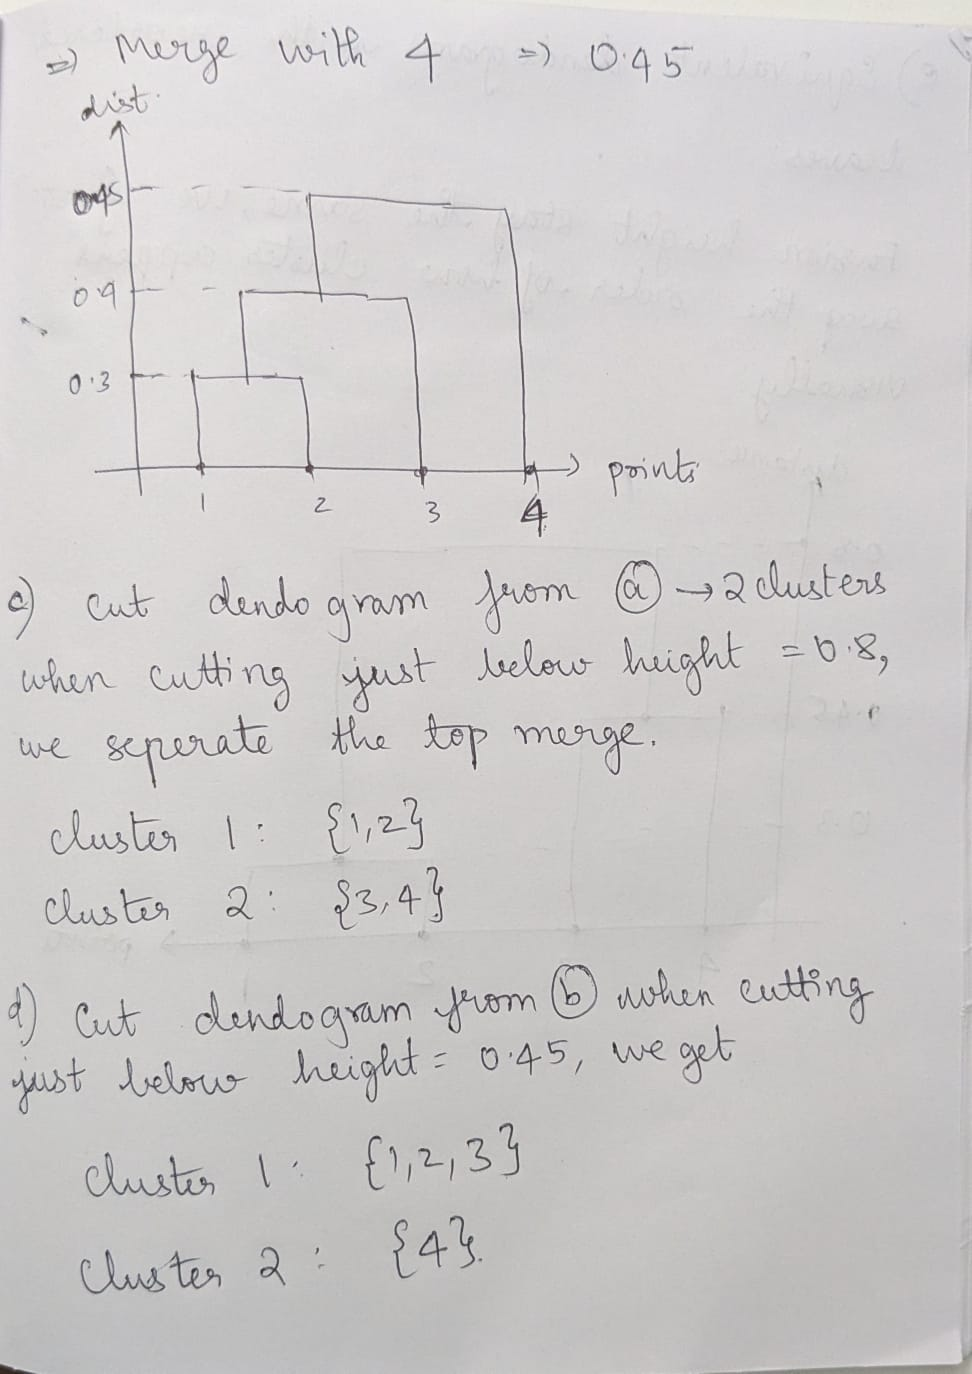

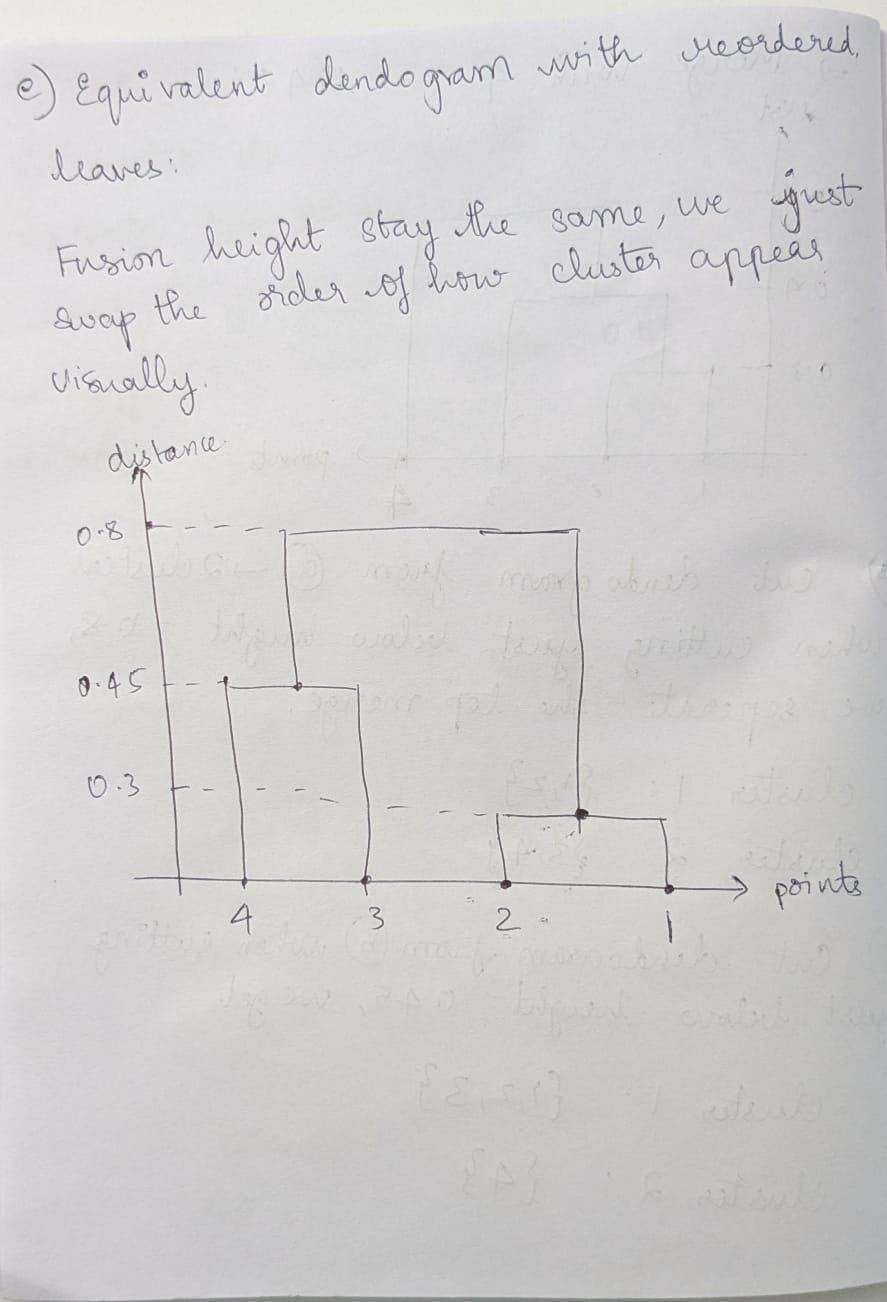